Importing necessary libraries

In [11]:
import numpy as np
import models.mlp as mlp
import matplotlib.pyplot as plt
import openml

Getting data

In [12]:
# Get dataset by ID
#Fasion MNIST id
dataset = openml.datasets.get_dataset(40996)

#Numpy data
#Catagorical and feat_names not needed
#X and Y are raw data, not to be used
X, Y, is_categorical, feat_names = dataset.get_data(
dataset_format="array", target=dataset.default_target_attribute)

/tmp/ipykernel_28674/3020315236.py:8: FutureWarning: Support for `dataset_format='array'` will be removed in 0.15,start using `dataset_format='dataframe' to ensure your code will continue to work. You can use the dataframe's `to_numpy` function to continue using numpy arrays.
  X, Y, is_categorical, feat_names = dataset.get_data(


Re-formating the data

In [13]:
#Function to catagorize the labels
#Y is 0 indexed
def categorize_labels(Y,length):
    temp = np.full(shape=(length,),fill_value=0,dtype=int)
    temp[Y] = 1
    return temp

In [14]:
#Testing categorize_labels function
y_output = categorize_labels(9, 10)
print(y_output)

[0 0 0 0 0 0 0 0 0 1]


In [15]:
#Normalizing the input
normalized_x = X/255.0
categorized_y = np.array([categorize_labels(y, 10) for y in Y])

In [16]:
x_input,x_test = normalized_x[:60000], normalized_x[60000:]
y_output,y_test = categorized_y[:60000], categorized_y[60000:]

Creating model

In [19]:
learning_rate = 0.001
model = mlp.Model([
    mlp.Linear(input_dim=784,output_dim=128,learning_rate=learning_rate,weight_init=mlp.WeightInitialization.He),
    mlp.Relu(),
    mlp.Linear(input_dim=128,output_dim=64,learning_rate=learning_rate,weight_init=mlp.WeightInitialization.He),
    mlp.Relu(),
    mlp.Linear(input_dim=64,output_dim=10,learning_rate=learning_rate,weight_init=mlp.WeightInitialization.Xavier),
    mlp.Softmax()
])

Training model

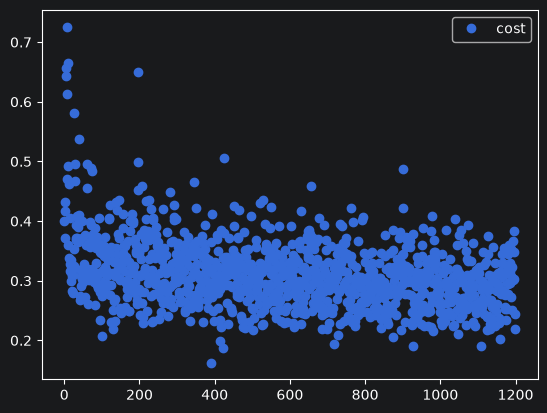

In [26]:
cost_history = model.advanced_train(x=x_input, y=y_output, epoch=10, batch_size=500, iterations=10000000, cutoff = 0, loss_function=mlp.LossFunction.CCE)
plt.plot(cost_history,'o',label='cost')
plt.legend()
plt.show()

Evaluating/ Testing model

In [27]:
test_output = model.forward_pass(x_test.T).T
test_output_numerated = np.argmax(test_output,axis=1,keepdims=False)
output_numerated = np.argmax(y_test,axis=1,keepdims=False)

hit_miss_map = np.where(test_output_numerated == output_numerated, 1, 0)
accuracy = np.sum(hit_miss_map)/hit_miss_map.shape[0]
print(f"Accuracy: {accuracy*100}%")

Accuracy: 87.42%
